In [43]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [45]:
%pip install numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_digits,
    load_iris
)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, SGDRegressor, LinearRegression
import time
print("All libraries imported successfully!")

All libraries imported successfully!


In [47]:
# Load Diabetes Dataset
diabetes = load_diabetes(scaled=False)

X_diabetes = diabetes.data
y_diabetes = diabetes.target


# Load Breast Cancer Dataset
cancer = load_breast_cancer()

X_cancer = cancer.data
y_cancer = 1 - cancer.target


# Load Digits Dataset
digits = load_digits()

X_digits = digits.data / 16.0
y_digits = digits.target


# Load Iris Dataset
iris = load_iris()

X_iris = iris.data
y_iris = iris.target

In [48]:
print("Diabetes:", X_diabetes.shape, y_diabetes.shape)
print("Breast Cancer:", X_cancer.shape, y_cancer.shape)
print("Digits:", X_digits.shape, y_digits.shape)
print("Iris:", X_iris.shape, y_iris.shape)

Diabetes: (442, 10) (442,)
Breast Cancer: (569, 30) (569,)
Digits: (1797, 64) (1797,)
Iris: (150, 4) (150,)


In [49]:
def split_data(X, y, is_classification=True):

    stratify_value = y if is_classification else None

    # First split: 80% training + validation, 20% testing
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify_value
    )

    stratify_train = y_train_val if is_classification else None

    # Second split: 75% training, 25% validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val,
        test_size=0.25,
        random_state=42,
        stratify=stratify_train
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

In [50]:
datasets = {
    "Diabetes": (X_diabetes, y_diabetes, False),
    "Breast Cancer": (X_cancer, y_cancer, True),
    "Digits": (X_digits, y_digits, True),
    "Iris": (X_iris, y_iris, True)
}

splits = {}

for name, (X, y, is_classification) in datasets.items():

    splits[name] = split_data(X, y, is_classification)

    print(f"\n{name}")

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]

    print("Training:", len(X_train))
    print("Validation:", len(X_val))
    print("Testing:", len(X_test))

    if is_classification:

        print("Class counts:")

        for split_name, labels in [
            ("Train", y_train),
            ("Validation", y_val),
            ("Test", y_test)
        ]:

            classes, counts = np.unique(labels, return_counts=True)

            print(split_name, dict(zip(classes, counts)))


Diabetes
Training: 264
Validation: 89
Testing: 89

Breast Cancer
Training: 341
Validation: 114
Testing: 114
Class counts:
Train {0: 214, 1: 127}
Validation {0: 71, 1: 43}
Test {0: 72, 1: 42}

Digits
Training: 1077
Validation: 360
Testing: 360
Class counts:
Train {0: 106, 1: 109, 2: 107, 3: 109, 4: 109, 5: 109, 6: 109, 7: 107, 8: 104, 9: 108}
Validation {0: 36, 1: 37, 2: 35, 3: 37, 4: 36, 5: 36, 6: 36, 7: 36, 8: 35, 9: 36}
Test {0: 36, 1: 36, 2: 35, 3: 37, 4: 36, 5: 37, 6: 36, 7: 36, 8: 35, 9: 36}

Iris
Training: 90
Validation: 30
Testing: 30
Class counts:
Train {0: 30, 1: 30, 2: 30}
Validation {0: 10, 1: 10, 2: 10}
Test {0: 10, 1: 10, 2: 10}


In [51]:
class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)

        self.std[self.std == 0] = 1

        return self

    def transform(self, X):
        return (X - self.mean) / self.std

In [52]:
X_diabetes_train, X_diabetes_val, X_diabetes_test, y_diabetes_train, y_diabetes_val, y_diabetes_test = splits["Diabetes"]

scaler = Standardizer()

X_train_scaled = scaler.fit(X_diabetes_train).transform(X_diabetes_train)

print("Means:", np.mean(X_train_scaled, axis=0))
print("Standard deviations:", np.std(X_train_scaled, axis=0))


Means: [-2.26249995e-16  1.79990702e-16 -2.23726761e-15 -3.61663561e-16
 -5.88754634e-17 -1.08348348e-17  1.94394164e-16 -4.03717464e-17
  2.03204457e-15 -5.53100810e-16]
Standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [53]:
def add_bias(X):
    return np.column_stack((np.ones(X.shape[0]), X))

In [54]:
X_test_bias = add_bias(np.array([[2, 3], [4, 5]]))

print(X_test_bias)


[[1. 2. 3.]
 [1. 4. 5.]]


In [55]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - (ss_res / ss_total)

In [56]:
y_true = np.array([1, 2, 3])
y_pred = np.array([1, 2, 4])

print("MSE:", mse(y_true, y_pred))
print("RMSE:", rmse(y_true, y_pred))
print("R2:", r2(y_true, y_pred))


MSE: 0.3333333333333333
RMSE: 0.5773502691896257
R2: 0.5


# Numerical gradient checking

In [57]:
def grad_check(f, grad, w, eps=1e-5):
    numerical_grad = np.zeros_like(w, dtype=float)

    for i in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += eps
        w_minus[i] -= eps

        numerical_grad[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    analytical_grad = grad(w)

    relative_error = np.linalg.norm(numerical_grad - analytical_grad) / max(
        np.linalg.norm(numerical_grad),
        np.linalg.norm(analytical_grad),
        1e-12
    )

    return relative_error

In [58]:
w_test = np.random.default_rng(42).normal(0, 0.1, 5)

f_test = lambda w: np.sum(w ** 2)
grad_test = lambda w: 2 * w

error = grad_check(f_test, grad_test, w_test)

print("Relative error:", error)

assert error < 1e-6, "Gradient check failed!"

print("Gradient check passed!")

Relative error: 1.1752888136783617e-12
Gradient check passed!


# Part B Linear regression

## Normal equation

### Implementing it

In [59]:
def normal_equation(X, y):
    X_bias = np.column_stack((np.ones(X.shape[0]), X))

    A = X_bias.T @ X_bias
    b = X_bias.T @ y

    w = np.linalg.solve(A, b)

    return w

### Mathematical derivation

The goal of Linear Regression is to find the weights that minimize the Mean Squared Error.

The cost function is:

J(w) = (1 / 2N) ||X_bias w - y||²

To find the minimum, we calculate the gradient and set it equal to zero:

∇J(w) = (1 / N) X_biasᵀ (X_bias w - y) = 0

Rearranging:

X_biasᵀ X_bias w = X_biasᵀ y

Therefore, the optimal weights are:

w* = (X_biasᵀ X_bias)⁻¹ X_biasᵀ y

In our implementation, we use np.linalg.solve() to calculate the weights instead of explicitly computing the matrix inverse. 

In [60]:
X_test = np.array([[1], [2], [3]], dtype=float)
y_test = np.array([2, 3, 5], dtype=float)

w_test = normal_equation(X_test, y_test)

print("Weights:", w_test)
print("Bias:", w_test[0])
print("Slope:", w_test[1])

Weights: [0.33333333 1.5       ]
Bias: 0.3333333333333333
Slope: 1.5


## Batch gradient descent

In [61]:
def linear_loss(X, y, w):
    predictions = X @ w
    loss = np.sum((predictions - y) ** 2) / (2 * len(y))
    return loss

In [62]:
def linear_gradient(X, y, w):
    predictions = X @ w
    gradient = (X.T @ (predictions - y)) / len(y)
    return gradient

In [63]:
def batch_gradient_descent(X, y, eta, epochs, w_star=None):
    w = np.zeros(X.shape[1])

    loss_history = []
    distance_history = []

    for epoch in range(epochs):
        gradient = linear_gradient(X, y, w)
        w = w - eta * gradient

        loss_history.append(linear_loss(X, y, w))

        if w_star is not None:
            distance = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)
            distance_history.append(distance)

    return w, np.array(loss_history), np.array(distance_history)

### Preparing diabetes dataset

In [64]:
# the splits
X_diabetes_train, X_diabetes_val, X_diabetes_test, y_diabetes_train, y_diabetes_val, y_diabetes_test = splits["Diabetes"]

# Standardize the features
diabetes_scaler = Standardizer()

X_diabetes_train_scaled = diabetes_scaler.fit(X_diabetes_train).transform(X_diabetes_train)
X_diabetes_val_scaled = diabetes_scaler.transform(X_diabetes_val)
X_diabetes_test_scaled = diabetes_scaler.transform(X_diabetes_test)

# Adding bias
X_diabetes_train_bias = add_bias(X_diabetes_train_scaled)
X_diabetes_val_bias = add_bias(X_diabetes_val_scaled)
X_diabetes_test_bias = add_bias(X_diabetes_test_scaled)

print("Training shape:", X_diabetes_train_bias.shape)
print("Validation shape:", X_diabetes_val_bias.shape)
print("Test shape:", X_diabetes_test_bias.shape)


Training shape: (264, 11)
Validation shape: (89, 11)
Test shape: (89, 11)


### getting optimal weights using Normal Equation

In [65]:
w_star = normal_equation(X_diabetes_train_scaled, y_diabetes_train)

print("Optimal weights:", w_star)
print("Number of weights:", len(w_star))

Optimal weights: [149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Number of weights: 11


In [71]:
feature_names = diabetes.feature_names

for name, weight in zip(["bias"] + list(feature_names), w_star):
    print(name, weight)

bias 149.81060606060603
age 1.131836758705169
sex -11.359310736067457
bmi 25.076618410484986
bp 15.167337918167021
s1 -51.1013594256263
s2 27.48082317876469
s3 10.840293926392714
s4 15.032148455382233
s5 37.2715876073178
s6 3.81711191007021


In [72]:
train_predictions = X_diabetes_train_bias @ w_star
val_predictions = X_diabetes_val_bias @ w_star
test_predictions = X_diabetes_test_bias @ w_star

print("Training RMSE:", rmse(y_diabetes_train, train_predictions))
print("Validation RMSE:", rmse(y_diabetes_val, val_predictions))
print("Test RMSE:", rmse(y_diabetes_test, test_predictions))
print("Test R2:", r2(y_diabetes_test, test_predictions))

condition_number = np.linalg.cond(
X_diabetes_train_bias.T @ X_diabetes_train_bias
)
print("Condition number:", condition_number)

Training RMSE: 54.6103635732402
Validation RMSE: 51.19371397853393
Test RMSE: 54.156412933260434
Test R2: 0.4464263764021126
Condition number: 505.70612269607483


In [73]:
linear_model = LinearRegression()
linear_model.fit(X_diabetes_train_scaled, y_diabetes_train)

sklearn_weights = np.concatenate((
[linear_model.intercept_],
linear_model.coef_
))

relative_error = (
np.linalg.norm(w_star - sklearn_weights)
/ np.linalg.norm(sklearn_weights)
)

print("Relative error:", relative_error)
print("Passed:", relative_error < 1e-6)

Relative error: 1.011372291326536e-14
Passed: True


### Checking linear regression gradient

In [66]:
def loss_function(w):
    return linear_loss(X_diabetes_train_bias, y_diabetes_train, w)


def gradient_function(w):
    return linear_gradient(X_diabetes_train_bias, y_diabetes_train, w)


w_check = np.random.default_rng(42).normal(
0, 0.1, X_diabetes_train_bias.shape[1]
)

error = grad_check(loss_function, gradient_function, w_check)

print("Relative error:", error)

assert error < 1e-6, "Gradient check failed!"

print("Linear regression gradient check passed!")

Relative error: 1.4148268371231586e-09
Linear regression gradient check passed!


## Comparing Learning Rates
We'll test different learning rates to see how they affect the convergence of Batch Gradient Descent.
Using  2000 epochs and comparing the final loss and distance from the optimal weights.

In [67]:
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]

results = {}

for eta in learning_rates:
    weights, losses, distances = batch_gradient_descent(
    X_diabetes_train_bias,
    y_diabetes_train,
    eta,
    2000,
    w_star
    )

    results[eta] = (weights, losses, distances)

    print("Learning rate:", eta)
    print("Final loss:", losses[-1])
    print("Final relative distance:", distances[-1])
    print()


Learning rate: 0.001
Final loss: 1723.4028887869279
Final relative distance: 0.4051130510143055

Learning rate: 0.01
Final loss: 1503.6866758289357
Final relative distance: 0.3345214298368573

Learning rate: 0.1
Final loss: 1491.8926356565873
Final relative distance: 0.08179228655115486

Learning rate: 0.5
Final loss: 1491.1459074694744
Final relative distance: 0.0001546261648138314

Learning rate: 1.0
Final loss: nan
Final relative distance: nan



/home/aseel/PycharmProjects/PythonProject4/.venv/lib/python3.8/site-packages/numpy/core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_144835/1933215590.py:3: RuntimeWarning: overflow encountered in square
  loss = np.sum((predictions - y) ** 2) / (2 * len(y))
/tmp/ipykernel_144835/494810295.py:3: RuntimeWarning: overflow encountered in matmul
  gradient = (X.T @ (predictions - y)) / len(y)
/tmp/ipykernel_144835/1933215590.py:2: RuntimeWarning: invalid value encountered in matmul
  predictions = X @ w
/tmp/ipykernel_144835/494810295.py:3: RuntimeWarning: invalid value encountered in matmul
  gradient = (X.T @ (predictions - y)) / len(y)


### Comparing Loss Across Learning Rates

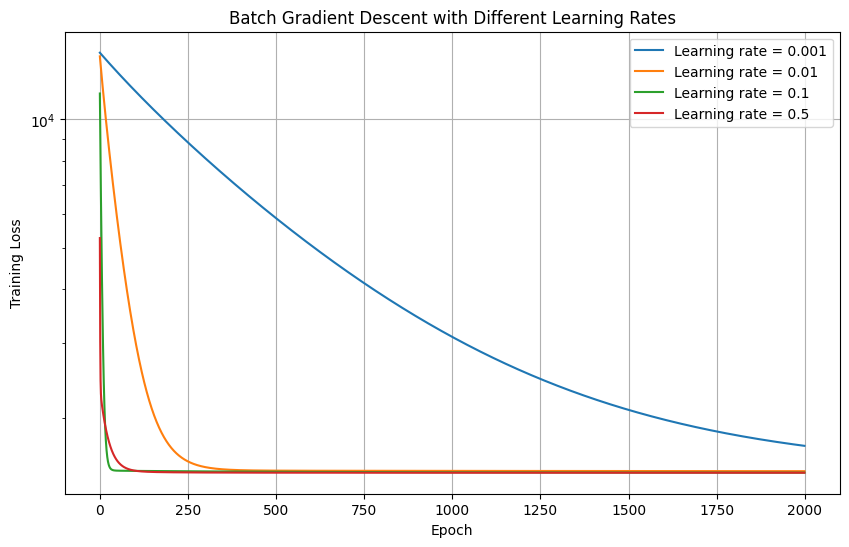

In [68]:
plt.figure(figsize=(10, 6))

for eta in learning_rates:
    losses = results[eta][1]

    if np.all(np.isfinite(losses)):
        plt.plot(losses, label=f"Learning rate = {eta}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Batch Gradient Descent with Different Learning Rates")
plt.legend()
plt.grid(True)

plt.show()

### First Epoch Reaching the Required Accuracy

In [69]:
for eta in learning_rates:
    distances = results[eta][2]

    successful_epochs = np.where(distances < 1e-3)[0]

    if len(successful_epochs) > 0:
        print("Learning rate:", eta)
        print("First successful epoch:", successful_epochs[0] + 1)
    else:
        print("Learning rate:", eta)
        print("Not reached within 2000 epochs")

Learning rate: 0.001
Not reached within 2000 epochs
Learning rate: 0.01
Not reached within 2000 epochs
Learning rate: 0.1
Not reached within 2000 epochs
Learning rate: 0.5
First successful epoch: 1524
Learning rate: 1.0
Not reached within 2000 epochs


In [70]:
# the Hessian matrix
N = X_diabetes_train_bias.shape[0]

H = (X_diabetes_train_bias.T @ X_diabetes_train_bias) / N

# eigenvalues
eigenvalues = np.linalg.eigvalsh(H)

# largest eigenvalue
lambda_max = eigenvalues[-1]

# max learning rate
eta_max = 2 / lambda_max

print("Largest eigenvalue:", lambda_max)
print("Maximum learning rate:", eta_max)

Largest eigenvalue: 3.9547550320503744
Maximum learning rate: 0.5057203249737277


In [71]:
eta_below = 0.95 * eta_max
eta_above = 1.05 * eta_max

# Testing learning rate below the limit
weights_below, losses_below, distances_below = batch_gradient_descent(
X_diabetes_train_bias,
y_diabetes_train,
eta_below,
2000,
w_star
)

# Testing learning rate above the limit
weights_above, losses_above, distances_above = batch_gradient_descent(
X_diabetes_train_bias,
y_diabetes_train,
eta_above,
2000,
w_star
)

print("Learning rate below limit:", eta_below)
print("Final loss:", losses_below[-1])
print("Final relative distance:", distances_below[-1])

print()

print("Learning rate above limit:", eta_above)
print("Final loss:", losses_above[-1])
print("Final relative distance:", distances_above[-1])

Learning rate below limit: 0.4804343087250412
Final loss: 1491.1459097339762
Final relative distance: 0.0002102307531352819

Learning rate above limit: 0.5310063412224141
Final loss: 3.244811817873191e+168
Final relative distance: 7.5818633424453655e+81


The largest eigenvalue of the Hessian was 3.9548, giving a theoretical maximum learning rate of approximately 0.5057. When using 95% of this limit (η = 0.4804), gradient descent converged and reached a relative distance below 10⁻³. However, when using 105% of the limit (η = 0.5310), the loss and relative distance grew, indicating divergence. This confirms that gradient descent converges only when the learning rate is greater than 0 and smaller that 2 divided by the largest eigenvalue of the Hessian matrix

### Why scaling/standardizing matters

In [72]:
# Adding bias column to original features
X_diabetes_train_raw_bias = add_bias(X_diabetes_train)

# raw Hessian
H_raw = (
X_diabetes_train_raw_bias.T @ X_diabetes_train_raw_bias
) / len(y_diabetes_train)

# condition number
condition_raw = np.linalg.cond(
X_diabetes_train_raw_bias.T @ X_diabetes_train_raw_bias
)

# largest eigenvalue
eigenvalues_raw = np.linalg.eigvalsh(H_raw)
lambda_max_raw = eigenvalues_raw[-1]

# maximum learning rate
eta_max_raw = 2 / lambda_max_raw

print("Raw feature condition number:", condition_raw)
print("Raw maximum learning rate:", eta_max_raw)


Raw feature condition number: 55778473.21753785
Raw maximum learning rate: 2.7427928748390996e-05


In [73]:
condition_scaled = np.linalg.cond(
X_diabetes_train_bias.T @ X_diabetes_train_bias
)

print("Standardized condition number:", condition_scaled)
print("Raw condition number:", condition_raw)

print()

print("Standardized maximum learning rate:", eta_max)
print("Raw maximum learning rate:", eta_max_raw)


Standardized condition number: 505.7061226960868
Raw condition number: 55778473.21753785

Standardized maximum learning rate: 0.5057203249737277
Raw maximum learning rate: 2.7427928748390996e-05


Standardization reduced the condition number from  55.8 million to 506. 
This makes the loss surface better conditioned and allows a much larger learning rate. 
The maximum learning rate increased from  0.0000274 to 0.5057 after standardization.
Raw features require much smaller learning rates and more epochs to converge, while standardization allows gradient descent to make faster and more stable progress.

### Repeating using the original features

In [74]:
# optimal weights for raw features
w_star_raw = normal_equation(
X_diabetes_train,
y_diabetes_train
)

In [75]:
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]

raw_results = {}

for eta in raw_learning_rates:
    weights, losses, distances = batch_gradient_descent(
    X_diabetes_train_raw_bias,
    y_diabetes_train,
    eta,
    2000,
    w_star_raw
)

    raw_results[eta] = (weights, losses, distances)

    print("Learning rate:", eta)
    print("Final loss:", losses[-1])
    print("Final relative distance:", distances[-1])
    print()

Learning rate: 1e-08
Final loss: 3583.5321022429885
Final relative distance: 0.9999985696135458

Learning rate: 1e-06
Final loss: 2388.75258220855
Final relative distance: 0.999967630212752

Learning rate: 1e-05
Final loss: 1827.5349100578878
Final relative distance: 0.9998463739822518

Learning rate: 0.0001
Final loss: nan
Final relative distance: nan



/tmp/ipykernel_144835/1933215590.py:3: RuntimeWarning: overflow encountered in square
  loss = np.sum((predictions - y) ** 2) / (2 * len(y))
/tmp/ipykernel_144835/494810295.py:3: RuntimeWarning: overflow encountered in matmul
  gradient = (X.T @ (predictions - y)) / len(y)
/tmp/ipykernel_144835/2997493346.py:9: RuntimeWarning: invalid value encountered in subtract
  w = w - eta * gradient


When using raw features, the learning rates 1e-8, 1e-6, and 1e-5 make very slow progress and remain far from the optimal weights after 2000 epochs.
A learning rate of 1e-4 causes divergence and produces NaN values. 
This shows that raw features require much smaller learning rates than standardized features.
Standardization improves the conditioning of the problem and allows gradient descent to converge much faster.

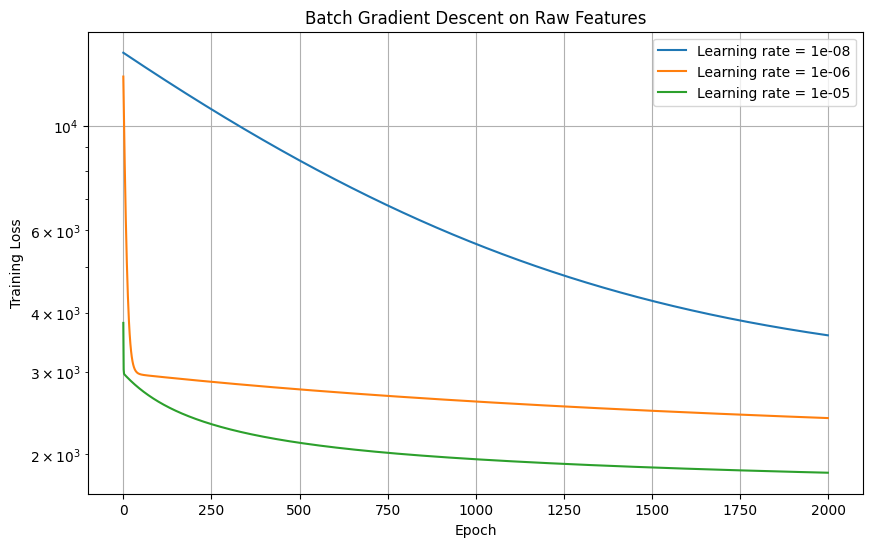

In [76]:
plt.figure(figsize=(10, 6))

for eta in raw_learning_rates:
    losses = raw_results[eta][1]

    if np.all(np.isfinite(losses)):
        plt.plot(losses, label=f"Learning rate = {eta}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Batch Gradient Descent on Raw Features")
plt.legend()
plt.grid(True)
plt.show()


In [77]:
for eta in raw_learning_rates:
    weights, losses, distances = raw_results[eta]

    successful_epochs = np.where(distances < 1e-3)[0]

    if len(successful_epochs) > 0:
        first_epoch = successful_epochs[0] + 1
    else:
        first_epoch = "Not reached"

    print(eta, losses[-1], distances[-1], first_epoch)
#learning rate-final loss-relative distance-first successful epoch 

1e-08 3583.5321022429885 0.9999985696135458 Not reached
1e-06 2388.75258220855 0.999967630212752 Not reached
1e-05 1827.5349100578878 0.9998463739822518 Not reached
0.0001 nan nan Not reached


### We'll implement a new gradient descent function because the existing one uses the whole dataset for every update.

In [44]:
def mini_batch_gradient_descent(X, y, eta, epochs, batch_size):
    w = np.zeros(X.shape[1])
    loss_history = []
    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        indices = rng.permutation(len(y))
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for i in range(0, len(y), batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            gradient = linear_gradient(X_batch, y_batch, w)
            w = w - eta * gradient

        loss = linear_loss(X, y, w)
        loss_history.append(loss)

    return w, np.array(loss_history)


### another gradient descent fn but it records it after every individual parameter update

In [74]:
def mini_batch_gradient_descent_updates(X, y, eta, epochs, batch_size):
    w = np.zeros(X.shape[1])
    epoch_losses = []
    update_losses = []
    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        indices = rng.permutation(len(y))
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for i in range(0, len(y), batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            gradient = linear_gradient(X_batch, y_batch, w)
            w = w - eta * gradient

            update_losses.append(linear_loss(X, y, w))

        epoch_losses.append(linear_loss(X, y, w))

    return w, np.array(epoch_losses), np.array(update_losses)

In [45]:
batch_sizes = [1, 16, 64, len(y_diabetes_train)]

mini_batch_results = {}

for B in batch_sizes:
    weights, losses = mini_batch_gradient_descent(
    X_diabetes_train_bias,
    y_diabetes_train,
    0.01,
    100,
    B
    )

    mini_batch_results[B] = (weights, losses)

    print("Batch size:", B)
    print("Final loss:", losses[-1])
    print()

Batch size: 1
Final loss: 1534.8083853086

Batch size: 16
Final loss: 1505.665099007747

Batch size: 64
Final loss: 1511.3753357143578

Batch size: 264
Final loss: 3085.440478999073



In [75]:
mini_batch_update_results = {}

for B in batch_sizes:
    weights, epoch_losses, update_losses = mini_batch_gradient_descent_updates(
    X_diabetes_train_bias,
    y_diabetes_train,
    0.01,
    100,
    B
    )

    mini_batch_update_results[B] = (weights, epoch_losses, update_losses)

    print("Batch size:", B)
    print("Number of parameter updates:", len(update_losses))
    print("Final loss:", update_losses[-1])
    print()


Batch size: 1
Number of parameter updates: 26400
Final loss: 1534.8083853086

Batch size: 16
Number of parameter updates: 1700
Final loss: 1505.665099007747

Batch size: 64
Number of parameter updates: 500
Final loss: 1511.3753357143578

Batch size: 264
Number of parameter updates: 100
Final loss: 3085.440478999073



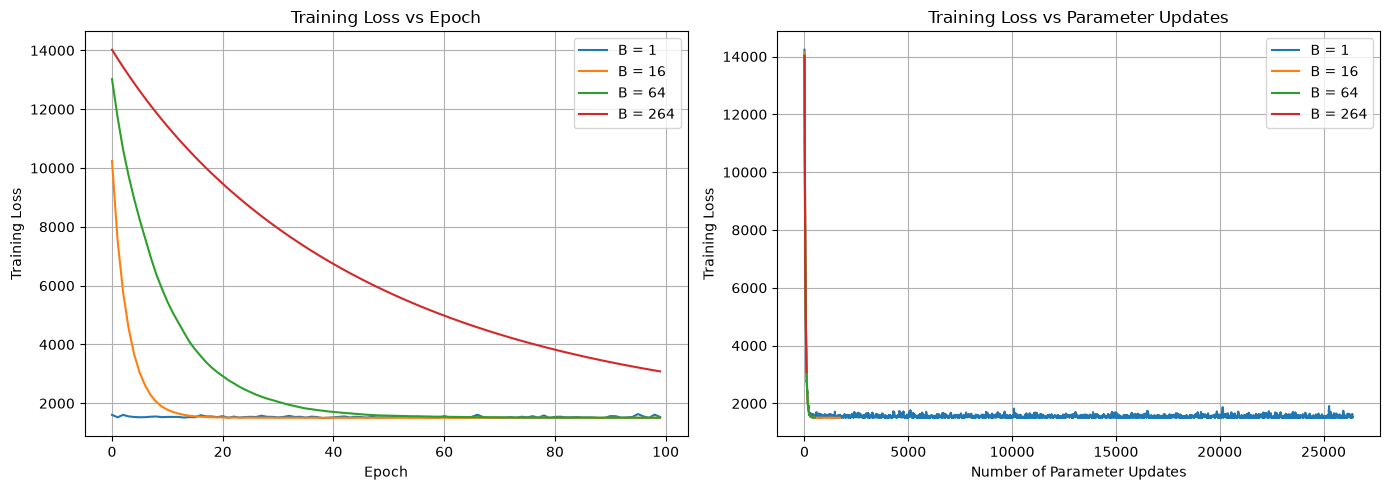

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:
    weights, losses = mini_batch_results[B]
    axes[0].plot(losses, label=f"B = {B}")

    weights, epoch_losses, update_losses = mini_batch_update_results[B]
    updates = np.arange(1, len(update_losses) + 1)
    axes[1].plot(updates, update_losses, label=f"B = {B}")

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")
axes[0].set_title("Training Loss vs Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Parameter Updates")
axes[1].set_ylabel("Training Loss")
axes[1].set_title("Training Loss vs Parameter Updates")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Smaller batch sizes make more parameter updates during each epoch. 

B=16 achieves the lowest final loss after 100 epochs, while B=1 performs better initially when comparing the same number of updates. 

B=1 produces noisier updates because each update uses only one training sample, while larger batches use more samples.

In [47]:
learning_rates_sgd = [0.001, 0.01, 0.1]
sgd_results = {}

for eta in learning_rates_sgd:
    weights, losses = mini_batch_gradient_descent(
    X_diabetes_train_bias,
    y_diabetes_train,
    eta,
    100,
    1
    )

    sgd_results[eta] = (weights, losses)

    print("Learning rate:", eta)
    print("Final loss:", losses[-1])
    print()


Learning rate: 0.001
Final loss: 1503.3121768105561

Learning rate: 0.01
Final loss: 1534.8083853086

Learning rate: 0.1
Final loss: 4186.980951940036



0.001 performs best. 

But learning rate 0.1 gives a much higher loss because the updates become unstable. 

This shows that sgd needs a suitable learning rate because individual samples produce noisy updates.

## Ridge regression(regularisation)

In [48]:
def ridge_regression(X, y, lam):
    X_bias = add_bias(X)

    I = np.eye(X_bias.shape[1])
    I[0, 0] = 0

    A = (X_bias.T @ X_bias) / len(y) + lam * I
    b = (X_bias.T @ y) / len(y)

    w = np.linalg.solve(A, b)

    return w

### the example in the pdf

In [49]:
X_toy = np.array([[1], [2], [3]])
y_toy = np.array([2, 3, 5])

w_toy = ridge_regression(X_toy, y_toy, 1)

print("Ridge weights:", w_toy)

Ridge weights: [2.13333333 0.6       ]


In [51]:
lambdas = [0] + list(np.logspace(-3, 1, 9))

ridge_results = {}

for lam in lambdas:
    w = ridge_regression(X_diabetes_train_scaled, y_diabetes_train, lam)

    train_predictions = X_diabetes_train_bias @ w
    val_predictions = X_diabetes_val_bias @ w
    test_predictions = X_diabetes_test_bias @ w

    ridge_results[lam] = {
    "weights": w,
    "train_rmse": rmse(y_diabetes_train, train_predictions),
    "val_rmse": rmse(y_diabetes_val, val_predictions),
    "test_rmse": rmse(y_diabetes_test, test_predictions)
    }

for lam in lambdas:
    print(
    "Lambda:", lam,
    "Validation RMSE:", ridge_results[lam]["val_rmse"]
    )

best_lambda = lambdas[0]

for lam in lambdas:
    if ridge_results[lam]["val_rmse"] < ridge_results[best_lambda]["val_rmse"]:
        best_lambda = lam

print("\nBest lambda:", best_lambda)
print("Test RMSE at best lambda:", ridge_results[best_lambda]["test_rmse"])
print("Test RMSE at lambda = 0:", ridge_results[0]["test_rmse"])

Lambda: 0 Validation RMSE: 51.19371397853393
Lambda: 0.001 Validation RMSE: 51.149556056831166
Lambda: 0.0031622776601683794 Validation RMSE: 51.10804077305133
Lambda: 0.01 Validation RMSE: 51.10474905057184
Lambda: 0.03162277660168379 Validation RMSE: 51.153130327383074
Lambda: 0.1 Validation RMSE: 51.20730458401005
Lambda: 0.31622776601683794 Validation RMSE: 51.577987730134396
Lambda: 1.0 Validation RMSE: 53.69512357732541
Lambda: 3.1622776601683795 Validation RMSE: 59.420332492276934
Lambda: 10.0 Validation RMSE: 66.95464908854308

Best lambda: 0.01
Test RMSE at best lambda: 53.95845214942079
Test RMSE at lambda = 0: 54.15641293326043


small lambda values produce lower validation error. 

The lowest error happens at lambda = 0.01, so this is our best value. 

When lambda becomes too large, the error increases because the model's weights become too small.

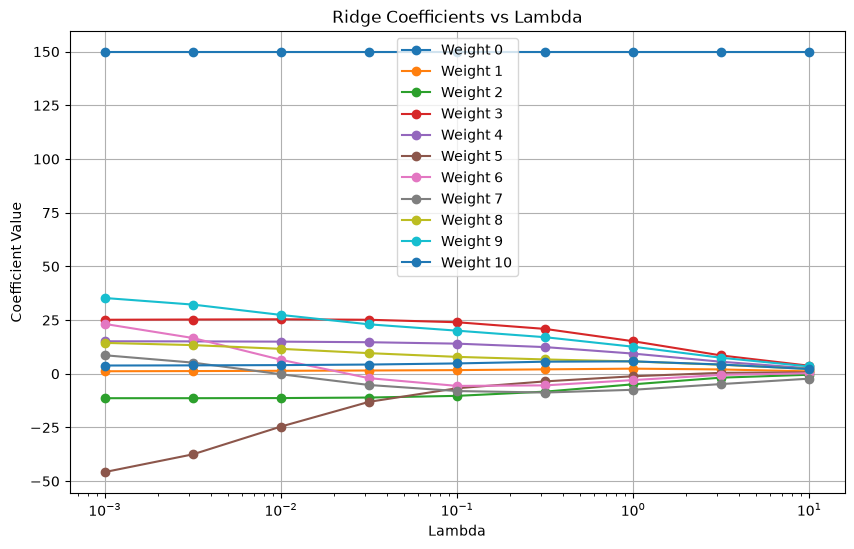

In [52]:
plt.figure(figsize=(10, 6))

for i in range(len(ridge_results[0.001]["weights"])):
    coefficients = []

    for lam in lambdas[1:]:
        coefficients.append(ridge_results[lam]["weights"][i])

    plt.plot(lambdas[1:], coefficients, marker="o", label=f"Weight {i}")

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients vs Lambda")
plt.legend()
plt.grid(True)
plt.show()

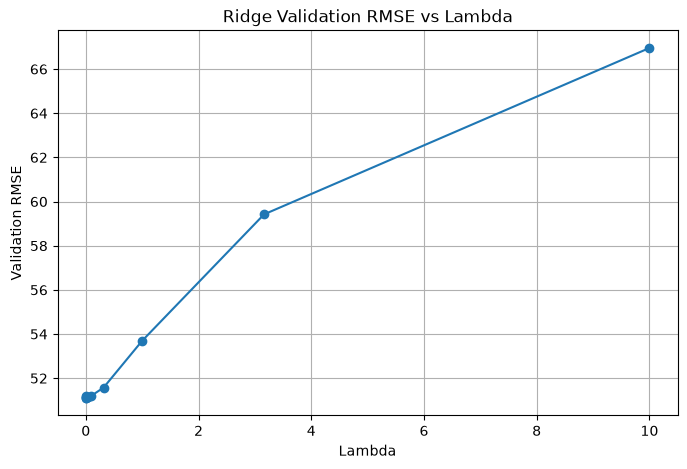

In [53]:
validation_errors = []

for lam in lambdas:
    validation_errors.append(ridge_results[lam]["val_rmse"])

plt.figure(figsize=(8, 5))
plt.plot(lambdas, validation_errors, marker="o")
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Ridge Validation RMSE vs Lambda")
plt.grid(True)
plt.show()

### Ridge regression with Degree-2 Features

In [54]:
def degree_two_features(X):
    new_features = [X]

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            if i == 1 and j == 1:
                continue

            new_features.append(X[:, i] * X[:, j])

    return np.column_stack(new_features)

In [55]:
X_train_poly = degree_two_features(X_diabetes_train)
X_val_poly = degree_two_features(X_diabetes_val)
X_test_poly = degree_two_features(X_diabetes_test)

print("Training shape:", X_train_poly.shape)
print("Validation shape:", X_val_poly.shape)
print("Testing shape:", X_test_poly.shape)

Training shape: (264, 64)
Validation shape: (89, 64)
Testing shape: (89, 64)


In [56]:
poly_scaler = Standardizer()

X_train_poly_scaled = poly_scaler.fit(X_train_poly).transform(X_train_poly)
X_val_poly_scaled = poly_scaler.transform(X_val_poly)
X_test_poly_scaled = poly_scaler.transform(X_test_poly)

X_train_poly_bias = add_bias(X_train_poly_scaled)
X_val_poly_bias = add_bias(X_val_poly_scaled)
X_test_poly_bias = add_bias(X_test_poly_scaled)

print("Training shape:", X_train_poly_bias.shape)
print("Validation shape:", X_val_poly_bias.shape)
print("Testing shape:", X_test_poly_bias.shape)

Training shape: (264, 65)
Validation shape: (89, 65)
Testing shape: (89, 65)


In [57]:
poly_ridge_results = {}

for lam in lambdas:
    w = ridge_regression(X_train_poly_scaled, y_diabetes_train, lam)

    train_predictions = X_train_poly_bias @ w
    val_predictions = X_val_poly_bias @ w
    test_predictions = X_test_poly_bias @ w

    poly_ridge_results[lam] = {
    "weights": w,
    "train_rmse": rmse(y_diabetes_train, train_predictions),
    "val_rmse": rmse(y_diabetes_val, val_predictions),
    "test_rmse": rmse(y_diabetes_test, test_predictions)
    }

for lam in lambdas:
    print(
    "Lambda:", lam,
    "Validation RMSE:", poly_ridge_results[lam]["val_rmse"]
    )

best_poly_lambda = lambdas[0]

for lam in lambdas:
    if poly_ridge_results[lam]["val_rmse"] < poly_ridge_results[best_poly_lambda]["val_rmse"]:
        best_poly_lambda = lam

print("\nBest lambda:", best_poly_lambda)
print("Test RMSE at best lambda:", poly_ridge_results[best_poly_lambda]["test_rmse"])
print("Test RMSE at lambda = 0:", poly_ridge_results[0]["test_rmse"])

Lambda: 0 Validation RMSE: 59.20594938231182
Lambda: 0.001 Validation RMSE: 54.20787063951846
Lambda: 0.0031622776601683794 Validation RMSE: 53.05319398672121
Lambda: 0.01 Validation RMSE: 52.10608851974406
Lambda: 0.03162277660168379 Validation RMSE: 51.47416985219737
Lambda: 0.1 Validation RMSE: 51.270639772934246
Lambda: 0.31622776601683794 Validation RMSE: 51.31625227479597
Lambda: 1.0 Validation RMSE: 51.49724346989616
Lambda: 3.1622776601683795 Validation RMSE: 52.63019328265264
Lambda: 10.0 Validation RMSE: 56.64033179006731

Best lambda: 0.1
Test RMSE at best lambda: 53.615580116744916
Test RMSE at lambda = 0: 62.13337339030653


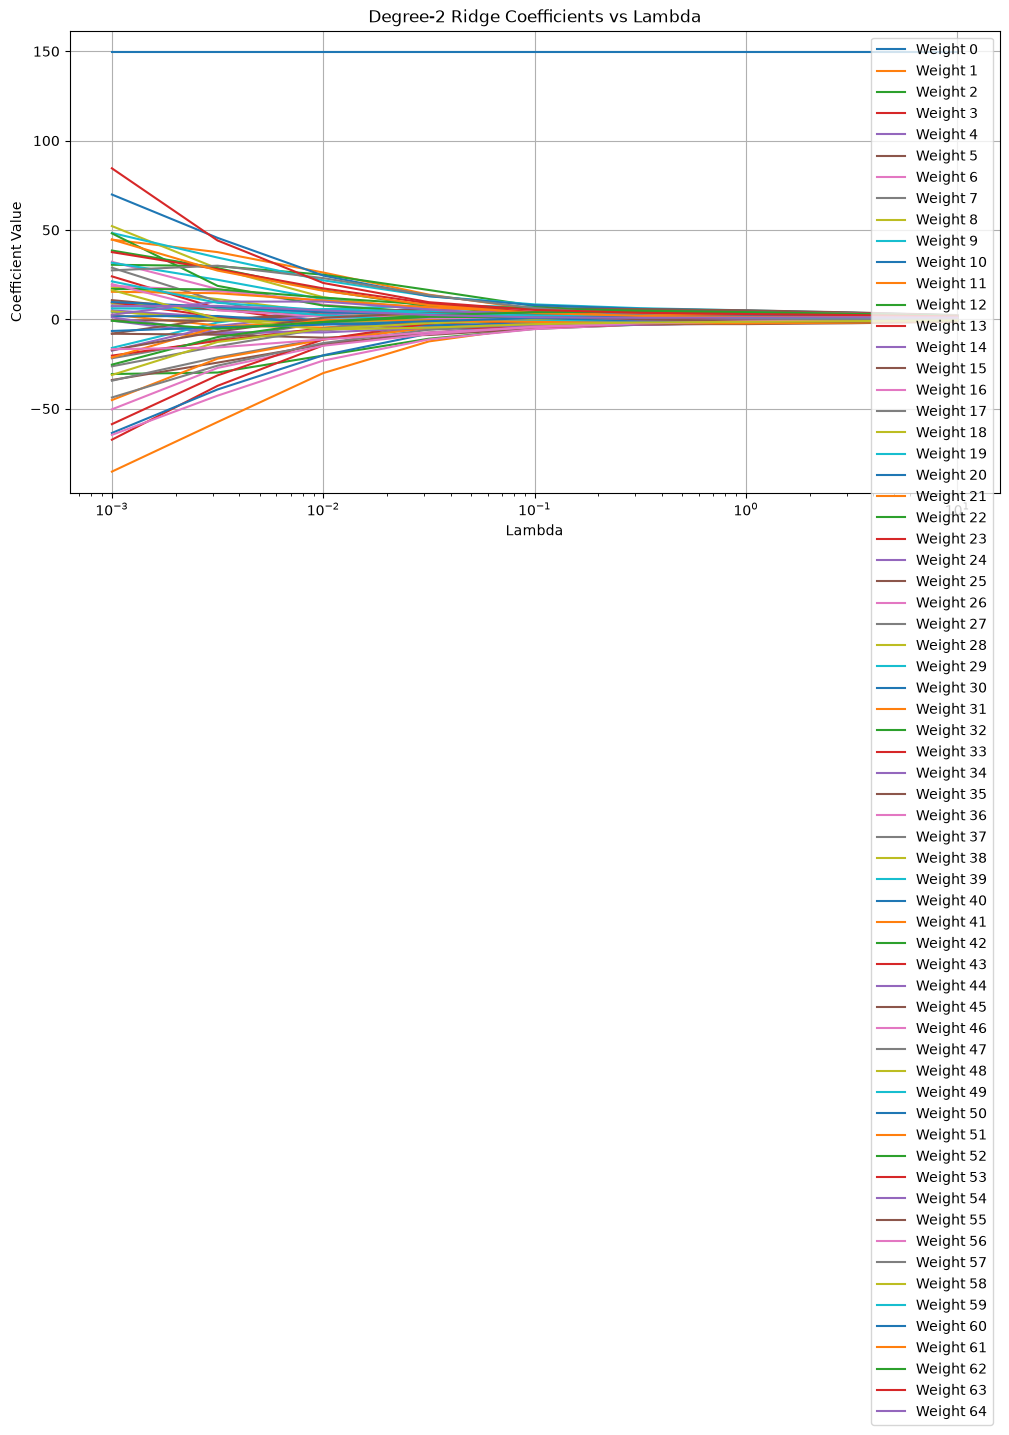

In [58]:
plt.figure(figsize=(12, 6))

for i in range(len(poly_ridge_results[0.001]["weights"])):
    coefficients = []

    for lam in lambdas[1:]:
        coefficients.append(poly_ridge_results[lam]["weights"][i])

    plt.plot(lambdas[1:], coefficients, label=f"Weight {i}")

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Degree-2 Ridge Coefficients vs Lambda")
plt.legend()
plt.grid(True)
plt.show()

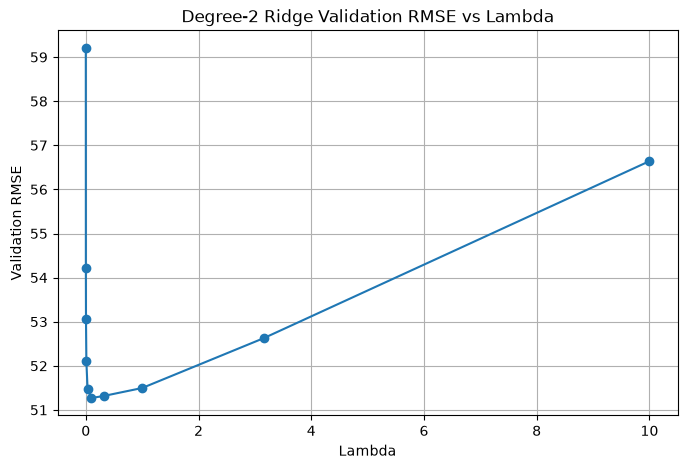

In [59]:
poly_validation_errors = []

for lam in lambdas:
    poly_validation_errors.append(poly_ridge_results[lam]["val_rmse"])

plt.figure(figsize=(8, 5))
plt.plot(lambdas, poly_validation_errors, marker="o")
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Degree-2 Ridge Validation RMSE vs Lambda")
plt.grid(True)
plt.show()

In [60]:
poly_condition = np.linalg.cond(X_train_poly_bias.T @ X_train_poly_bias)

print("Degree-2 condition number:", poly_condition)

Degree-2 condition number: 1289356243.5948882


very large condition number which shows features are highly related, so the calculations are less stable and more sensitive

In [61]:
ridge_lambda = 0.1
eta = 0.4
epochs = 3000

w_ridge_star = ridge_regression(
X_diabetes_train_scaled,
y_diabetes_train,
ridge_lambda
)

w_ridge_gd = np.zeros(X_diabetes_train_bias.shape[1])

for epoch in range(epochs):
    gradient = linear_gradient(
    X_diabetes_train_bias,
    y_diabetes_train,
    w_ridge_gd
    )

    gradient[1:] += ridge_lambda * w_ridge_gd[1:]

    w_ridge_gd = w_ridge_gd - eta * gradient

relative_distance = np.linalg.norm(w_ridge_gd - w_ridge_star) / np.linalg.norm(w_ridge_star)

print("Relative distance:", relative_distance)
print("Passed:", relative_distance < 1e-6)

Relative distance: 7.903389247062618e-16
Passed: True


In [64]:
ridge_model = Ridge(alpha=0.1 * len(y_diabetes_train))
ridge_model.fit(X_diabetes_train_scaled, y_diabetes_train)

sklearn_weights = np.concatenate(([ridge_model.intercept_], ridge_model.coef_))

relative_error = np.linalg.norm(w_ridge_star - sklearn_weights) / np.linalg.norm(sklearn_weights)

print("Relative error:", relative_error)
print("Passed:", relative_error < 1e-6)

Relative error: 1.3597107815012646e-15
Passed: True


When we have more training samples, the model has more data to learn from, which can help make the results more reliable. 

When we increase the number of features, the model becomes more complicated and may overfit the training data. 

Ridge helps by making the feature weights smaller. We don't penalize the bias because it controls the starting prediction, and we don't want to force it to become zero.

### Task 10 Comparing regression models

In [70]:
comparison_results = []

#Normal Eq
start = time.perf_counter()
w_normal = normal_equation(X_diabetes_train_scaled, y_diabetes_train)
normal_time = time.perf_counter() - start

predictions = X_diabetes_test_bias @ w_normal

comparison_results.append({
"Method": "Normal Equation",
"Test RMSE": rmse(y_diabetes_test, predictions),
"Relative Distance": np.linalg.norm(w_normal - w_star) / np.linalg.norm(w_star),
"Fit Time": normal_time
})


# Batch Gradient Descent
start = time.perf_counter()
w_batch, batch_losses, batch_distances = batch_gradient_descent(
X_diabetes_train_bias, y_diabetes_train, 0.5, 2000
)
batch_time = time.perf_counter() - start

predictions = X_diabetes_test_bias @ w_batch

comparison_results.append({
"Method": "Batch GD",
"Test RMSE": rmse(y_diabetes_test, predictions),
"Relative Distance": np.linalg.norm(w_batch - w_star) / np.linalg.norm(w_star),
"Fit Time": batch_time
})


# Mini-batch Gradient Descent
start = time.perf_counter()
w_mini, mini_losses = mini_batch_gradient_descent(
X_diabetes_train_bias, y_diabetes_train, 0.01, 100, 16
)
mini_time = time.perf_counter() - start

predictions = X_diabetes_test_bias @ w_mini

comparison_results.append({
"Method": "Mini-batch GD",
"Test RMSE": rmse(y_diabetes_test, predictions),
"Relative Distance": np.linalg.norm(w_mini - w_star) / np.linalg.norm(w_star),
"Fit Time": mini_time
})


#Ridge Regression
start = time.perf_counter()
w_ridge = ridge_regression(
X_diabetes_train_scaled, y_diabetes_train, 0.1
)
ridge_time = time.perf_counter() - start

predictions = X_diabetes_test_bias @ w_ridge

comparison_results.append({
"Method": "Ridge Regression",
"Test RMSE": rmse(y_diabetes_test, predictions),
"Relative Distance": np.linalg.norm(w_ridge - w_ridge_star) / np.linalg.norm(w_ridge_star),
"Fit Time": ridge_time
})


#sklearn Linear Regression
linear_model = LinearRegression()

start = time.perf_counter()
linear_model.fit(X_diabetes_train_scaled, y_diabetes_train)
linear_time = time.perf_counter() - start

linear_weights = np.concatenate(([linear_model.intercept_], linear_model.coef_))
predictions = linear_model.predict(X_diabetes_test_scaled)

comparison_results.append({
"Method": "sklearn LinearRegression",
"Test RMSE": rmse(y_diabetes_test, predictions),
"Relative Distance": np.linalg.norm(linear_weights - w_star) / np.linalg.norm(w_star),
"Fit Time": linear_time
})


#sklearn Ridge
ridge_model = Ridge(alpha=0.1 * len(y_diabetes_train))

start = time.perf_counter()
ridge_model.fit(X_diabetes_train_scaled, y_diabetes_train)
sklearn_ridge_time = time.perf_counter() - start

sklearn_ridge_weights = np.concatenate(([ridge_model.intercept_], ridge_model.coef_))
predictions = ridge_model.predict(X_diabetes_test_scaled)

comparison_results.append({
"Method": "sklearn Ridge",
"Test RMSE": rmse(y_diabetes_test, predictions),
"Relative Distance": np.linalg.norm(sklearn_ridge_weights - w_ridge_star) / np.linalg.norm(w_ridge_star),
"Fit Time": sklearn_ridge_time
})


# sklearn SGDRegressor with different learning rates
for eta in [0.001, 0.01, 0.1]:
    sgd_model = SGDRegressor(
    eta0=eta,
    max_iter=1000,
    tol=None,
    random_state=42
    )

    start = time.perf_counter()
    sgd_model.fit(X_diabetes_train_scaled, y_diabetes_train)
    sgd_time = time.perf_counter() - start

    sgd_weights = np.concatenate(([sgd_model.intercept_[0]], sgd_model.coef_))
    predictions = sgd_model.predict(X_diabetes_test_scaled)

    comparison_results.append({
    "Method": f"SGDRegressor eta={eta}",
    "Test RMSE": rmse(y_diabetes_test, predictions),
    "Relative Distance": np.linalg.norm(sgd_weights - w_star) / np.linalg.norm(w_star),
    "Fit Time": sgd_time
    })


comparison_table = pd.DataFrame(comparison_results)
print(comparison_table.to_string(index=False))

                  Method  Test RMSE  Relative Distance  Fit Time
         Normal Equation  54.156413       0.000000e+00  0.000144
                Batch GD  54.156254       1.546262e-04  0.020281
           Mini-batch GD  53.895449       3.421471e-01  0.006517
        Ridge Regression  53.708925       0.000000e+00  0.000069
sklearn LinearRegression  54.156413       1.011372e-14  0.000536
           sklearn Ridge  53.708925       1.359711e-15  0.000370
  SGDRegressor eta=0.001  53.929786       3.465483e-01  0.007621
   SGDRegressor eta=0.01  54.051346       1.178586e-01  0.007516
    SGDRegressor eta=0.1  54.191451       1.990861e-02  0.007160


The Normal Equation and sklearn LinearRegression produce almost identical results, confirming that our implementation is correct. 

And our Ridge Regression implementation closely matches sklearn Ridge. 

Batch Gradient Descent also achieves a result very close to the exact solution, while Mini-batch GD and SGDRegressor produce approximate solutions due to their iterative weight updates. 

The learning rate affects the performance of SGDRegressor, with 0.001 achieving the lowest test RMSE among the three tested values.

Part C

In [82]:
# Extract Breast Cancer splits
X_cancer_train, X_cancer_val, X_cancer_test, y_cancer_train, y_cancer_val, y_cancer_test = splits["Breast Cancer"]

# Standardize features using training data only
cancer_scaler = Standardizer()

cancer_scaler.fit(X_cancer_train)

X_cancer_train_std = cancer_scaler.transform(X_cancer_train)
X_cancer_val_std = cancer_scaler.transform(X_cancer_val)
X_cancer_test_std = cancer_scaler.transform(X_cancer_test)

# Add bias column
X_cancer_train_bias = add_bias(X_cancer_train_std)
X_cancer_val_bias = add_bias(X_cancer_val_std)
X_cancer_test_bias = add_bias(X_cancer_test_std)

# Check shapes
print("Training:", X_cancer_train_bias.shape)
print("Validation:", X_cancer_val_bias.shape)
print("Testing:", X_cancer_test_bias.shape)

print("First 5 feature means:")
print(np.round(X_cancer_train_std.mean(axis=0)[:5], 6))

Training: (341, 31)
Validation: (114, 31)
Testing: (114, 31)
First 5 feature means:
[ 0.  0. -0.  0. -0.]


In [83]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)

    result = np.empty_like(z)

    positive = z >= 0
    result[positive] = 1.0 / (1.0 + np.exp(-z[positive]))

    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1.0 + exp_z)

    return result

In [84]:
test_values = np.array([-800, -2, 0, 2, 800])

print(sigmoid(test_values))

[0.         0.11920292 0.5        0.88079708 1.        ]


In [85]:
def logistic_loss(X, y, w, lam):
    z = X @ w

    data_loss = np.mean(np.logaddexp(0, z) - y * z)

    regularization = (lam / 2) * np.sum(w[1:] ** 2)

    return data_loss + regularization

In [86]:
def logistic_gradient(X, y, w, lam):
    p = sigmoid(X @ w)

    grad = X.T @ (p - y) / len(y)

    grad[1:] += lam * w[1:]

    return grad

In [87]:
w_test = np.random.default_rng(42).normal(
    0, 0.1, X_cancer_train_bias.shape[1]
)

lam = 0.1

error = grad_check(
    lambda w: logistic_loss(X_cancer_train_bias, y_cancer_train, w, lam),
    lambda w: logistic_gradient(X_cancer_train_bias, y_cancer_train, w, lam),
    w_test
)

print("Relative error:", error)

assert error < 1e-6, "Gradient check failed!"

print("Logistic regression gradient check passed!")

Relative error: 1.8993199008694766e-11
Logistic regression gradient check passed!


In [88]:
def predict_proba(X, w):
    return sigmoid(X @ w)


def predict(X, w, threshold=0.5):
    return (predict_proba(X, w) >= threshold).astype(int)


def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

In [89]:
def logistic_gradient_descent(X, y, lam, learning_rate=0.5, epochs=3000):
    w = np.zeros(X.shape[1])

    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):
        grad = logistic_gradient(X, y, w, lam)

        w = w - learning_rate * grad

        loss = logistic_loss(X, y, w, lam)
        predictions = predict(X, w)

        train_losses.append(loss)
        train_accuracies.append(accuracy(y, predictions))

    return w, train_losses, train_accuracies

In [90]:
lambda_values = [0, 0.001, 0.01, 0.1, 1]

results = {}

for lam in lambda_values:

    # Train the model
    w, train_losses, train_accuracies = logistic_gradient_descent(
        X_cancer_train_bias,
        y_cancer_train,
        lam=lam,
        learning_rate=0.5,
        epochs=3000
    )

    # Evaluate on training data
    train_predictions = predict(X_cancer_train_bias, w)
    train_acc = accuracy(y_cancer_train, train_predictions)

    # Evaluate on validation data
    val_predictions = predict(X_cancer_val_bias, w)
    val_acc = accuracy(y_cancer_val, val_predictions)

    val_loss = logistic_loss(
        X_cancer_val_bias, y_cancer_val, w, lam
    )

    # Store results
    results[lam] = {
        "weights": w,
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "weights_norm": np.linalg.norm(w[1:])
    }

In [91]:
results_table = pd.DataFrame([
    {
        "Lambda": lam,
        "Train Accuracy": results[lam]["train_accuracy"],
        "Validation Accuracy": results[lam]["val_accuracy"],
        "Validation Loss": results[lam]["val_loss"],
        "Weights Norm": results[lam]["weights_norm"]
    }
    for lam in lambda_values
])

print(results_table.to_string(index=False))

 Lambda  Train Accuracy  Validation Accuracy  Validation Loss  Weights Norm
  0.000        0.994135             0.973684         0.084192      8.132231
  0.001        0.988270             0.973684         0.086207      5.099928
  0.010        0.985337             0.973684         0.110010      2.325749
  0.100        0.973607             0.973684         0.202665      1.105547
  1.000        0.938416             0.956140         0.389668      0.441485


In [92]:
best_lambda = min(
    lambda_values,
    key=lambda lam: results[lam]["val_loss"]
)

best_model = results[best_lambda]["weights"]

print("Best Lambda:", best_lambda)
print("Best Validation Loss:", results[best_lambda]["val_loss"])
print("Best Validation Accuracy:", results[best_lambda]["val_accuracy"])

Best Lambda: 0
Best Validation Loss: 0.08419249601904283
Best Validation Accuracy: 0.9736842105263158


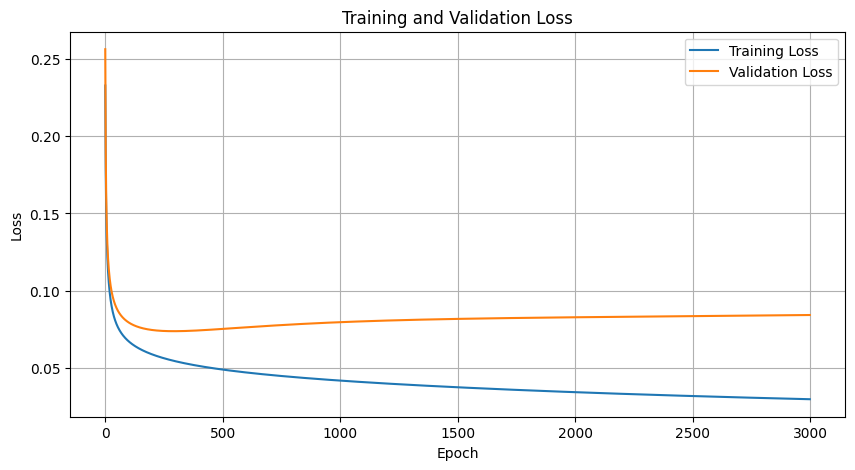

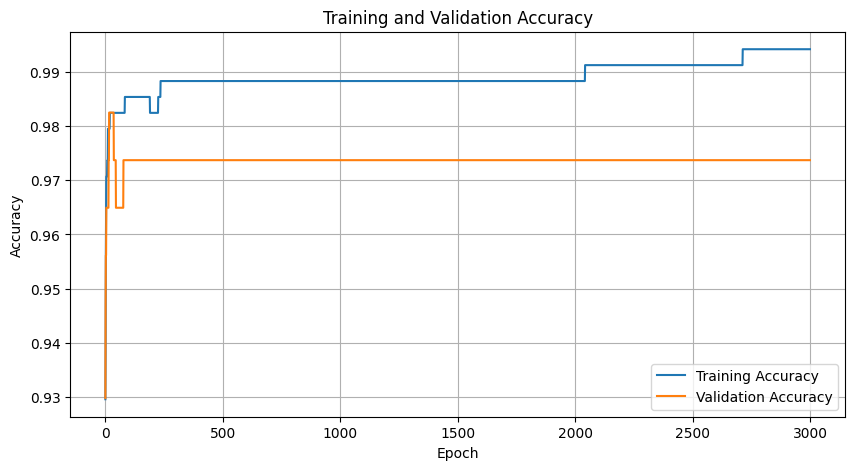

In [93]:
best_lambda = 0

best_train_losses = results[best_lambda]["train_losses"]
best_train_accuracies = results[best_lambda]["train_accuracies"]

# Calculate validation metrics for each epoch
val_losses = []
val_accuracies = []

w = np.zeros(X_cancer_train_bias.shape[1])

for epoch in range(3000):
    grad = logistic_gradient(
        X_cancer_train_bias, y_cancer_train, w, best_lambda
    )

    w = w - 0.5 * grad

    val_losses.append(
        logistic_loss(X_cancer_val_bias, y_cancer_val, w, best_lambda)
    )

    val_accuracies.append(
        accuracy(y_cancer_val, predict(X_cancer_val_bias, w))
    )

# Plot losses
plt.figure(figsize=(10, 5))
plt.plot(best_train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

# Plot accuracies
plt.figure(figsize=(10, 5))
plt.plot(best_train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [94]:
learning_rates = [0.01, 0.1, 1, 5, 20]

lr_results = []

for eta in learning_rates:

    w, losses, accuracies = logistic_gradient_descent(
        X_cancer_train_bias,
        y_cancer_train,
        lam=0.01,
        learning_rate=eta,
        epochs=1000
    )

    final_loss = losses[-1]

    lr_results.append({
        "Learning Rate": eta,
        "Final Training Loss": final_loss
    })

lr_table = pd.DataFrame(lr_results)

print(lr_table.to_string(index=False))

 Learning Rate  Final Training Loss
          0.01             0.116289
          0.10             0.098311
          1.00             0.098112
          5.00             0.098112
         20.00             0.629483


In [95]:
best_model = results[best_lambda]["weights"]

test_predictions = predict(X_cancer_test_bias, best_model)

test_accuracy = accuracy(y_cancer_test, test_predictions)

print("Best Lambda:", best_lambda)
print("Final Test Accuracy:", test_accuracy)

Best Lambda: 0
Final Test Accuracy: 0.9736842105263158


In [96]:
# Task 13: Logistic Regression without Regularization

lam = 0
learning_rate = 0.5
epochs = 20000

w = np.zeros(X_cancer_train_bias.shape[1])

weights_norm = []
training_loss = []

for epoch in range(epochs):

    grad = logistic_gradient(
        X_cancer_train_bias,
        y_cancer_train,
        w,
        lam
    )

    w = w - learning_rate * grad

    weights_norm.append(np.linalg.norm(w[1:]))

    training_loss.append(
        logistic_loss(
            X_cancer_train_bias,
            y_cancer_train,
            w,
            lam
        )
    )

print("Final Weights Norm:", weights_norm[-1])
print("Final Training Loss:", training_loss[-1])

Final Weights Norm: 19.07910409109684
Final Training Loss: 0.011458238949846758


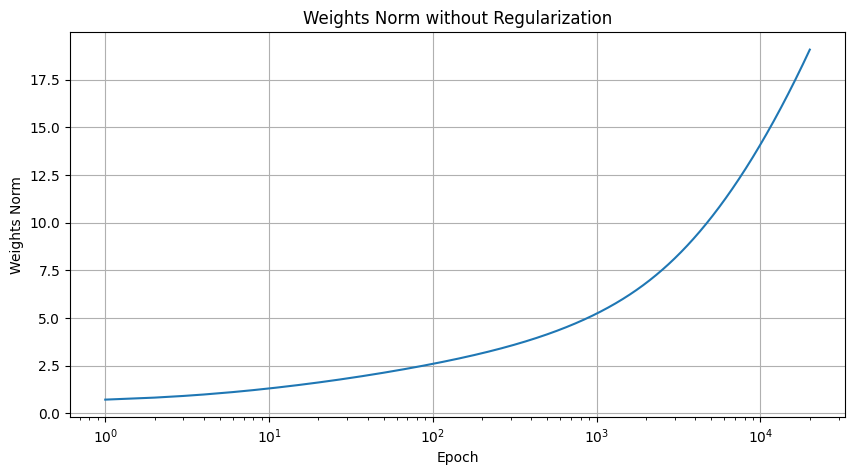

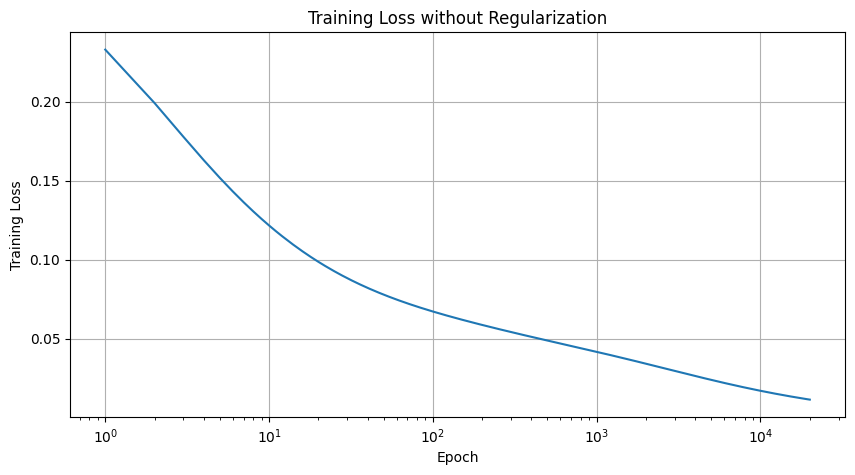

In [97]:
# Plot weights norm
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), weights_norm)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Weights Norm")
plt.title("Weights Norm without Regularization")
plt.grid()
plt.show()


# Plot training loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), training_loss)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss without Regularization")
plt.grid()
plt.show()

**Task 13 – Separability**

The training set appears to be linearly separable, as the training loss keeps decreasing while the norm of the weights keeps increasing during training without regularization.

For linearly separable data, the logistic loss can approach zero by continuously increasing the magnitude of the weights. However, it never reaches zero for any finite weights. Therefore, the loss has an infimum but no finite minimizer.

L2 regularization solves this problem by adding a penalty on the squared magnitude of the weights. This prevents the weights from growing indefinitely and encourages a finite optimal solution.

In [98]:
from sklearn.linear_model import LogisticRegression

In [99]:
sklearn_results = {}

for lam in lambda_values:

    if lam == 0:
        model = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=100000
        )
    else:
        C = 1 / (lam * len(y_cancer_train))

        model = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=100000
        )

    # Train the model
    model.fit(X_cancer_train_std, y_cancer_train)

    # Evaluate the model
    train_pred = model.predict(X_cancer_train_std)
    val_pred = model.predict(X_cancer_val_std)

    sklearn_results[lam] = {
        "model": model,
        "train_accuracy": accuracy(y_cancer_train, train_pred),
        "val_accuracy": accuracy(y_cancer_val, val_pred)
    }

In [100]:
lam = 0.01

# Get our model weights from Task 12
w_scratch = results[lam]["weights"]

# Train sklearn with the required settings
sklearn_model = LogisticRegression(
    C=1 / (lam * len(y_cancer_train)),
    solver="lbfgs",
    tol=1e-12,
    max_iter=100000
)

sklearn_model.fit(X_cancer_train_std, y_cancer_train)

# Combine intercept and coefficients
w_sklearn = np.concatenate((
    sklearn_model.intercept_,
    sklearn_model.coef_[0]
))

# Calculate relative error
relative_error = np.linalg.norm(
    w_scratch - w_sklearn
) / max(
    np.linalg.norm(w_scratch),
    np.linalg.norm(w_sklearn),
    1e-12
)

# Compare predictions
pred_scratch = predict(X_cancer_test_bias, w_scratch)
pred_sklearn = sklearn_model.predict(X_cancer_test_std)

predictions_agree = np.array_equal(
    pred_scratch,
    pred_sklearn
)

print("Relative Error:", relative_error)
print("Predictions Agree:", predictions_agree)

Relative Error: 4.78794968711774e-05
Predictions Agree: True


In [101]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

C_results = []

for C in C_values:

    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100000
    )

    model.fit(X_cancer_train_std, y_cancer_train)

    train_pred = model.predict(X_cancer_train_std)
    val_pred = model.predict(X_cancer_val_std)
    test_pred = model.predict(X_cancer_test_std)

    C_results.append({
        "C": C,
        "Train Accuracy": accuracy(y_cancer_train, train_pred),
        "Validation Accuracy": accuracy(y_cancer_val, val_pred),
        "Test Accuracy": accuracy(y_cancer_test, test_pred)
    })

C_table = pd.DataFrame(C_results)

print(C_table.to_string(index=False))

       C  Train Accuracy  Validation Accuracy  Test Accuracy
   0.001        0.879765             0.903509       0.868421
   0.010        0.950147             0.964912       0.947368
   0.100        0.979472             0.982456       0.982456
   1.000        0.988270             0.973684       0.973684
  10.000        0.997067             0.964912       0.964912
 100.000        1.000000             0.956140       0.956140
1000.000        1.000000             0.956140       0.956140


In [102]:
import time

C_compare = 1 / (0.01 * len(y_cancer_train))

solver_names = ["lbfgs", "liblinear", "saga"]

solver_results = []
solver_models = {}

for solver in solver_names:
    model = LogisticRegression(
        C=C_compare,
        solver=solver,
        max_iter=100000,
        tol=1e-8,
        random_state=42
    )

    start_time = time.perf_counter()
    model.fit(X_cancer_train_std, y_cancer_train)
    fit_time = time.perf_counter() - start_time

    solver_models[solver] = model

    solver_results.append({
        "Solver": solver,
        "Iterations": int(model.n_iter_[0]),
        "Fit Time (s)": fit_time,
        "Intercept": model.intercept_[0],
        "Coefficient Norm": np.linalg.norm(model.coef_),
        "Train Accuracy": accuracy(
            y_cancer_train, model.predict(X_cancer_train_std)
        ),
        "Validation Accuracy": accuracy(
            y_cancer_val, model.predict(X_cancer_val_std)
        )
    })

# Compare coefficients with lbfgs
reference_coef = solver_models["lbfgs"].coef_.ravel()

for i, solver in enumerate(solver_names):
    difference = np.linalg.norm(
        solver_models[solver].coef_.ravel() - reference_coef
    )
    solver_results[i]["Coefficient Difference"] = difference

solver_table = pd.DataFrame(solver_results)
print(solver_table.to_string(index=False))

   Solver  Iterations  Fit Time (s)  Intercept  Coefficient Norm  Train Accuracy  Validation Accuracy  Coefficient Difference
    lbfgs          21      0.028086  -0.423813          2.325756        0.985337             0.973684                0.000000
liblinear          10      0.005604  -0.287900          2.347991        0.985337             0.973684                0.089385
     saga         770      0.094051  -0.423817          2.325749        0.985337             0.973684                0.000113


Task 14 – Comparison of Logistic Regression Solvers

Three solvers (lbfgs, liblinear, and saga) were compared using the same regularization parameter (C).
All three solvers achieved the same training accuracy (98.53%) and validation accuracy (97.37%).

Discussion:

liblinear was the fastest solver in this experiment, requiring only 10 iterations.

lbfgs converged in 21 iterations and provided results very close to saga.

saga required more iterations and time, but its coefficients were almost identical to those obtained using lbfgs.

Why does liblinear behave differently?

Unlike lbfgs and saga, liblinear regularizes the intercept by default. This can lead to different intercept and coefficient values. However, the three solvers achieved the same classification accuracy on the training and validation sets.

Conclusion:

Although the solvers differ in convergence speed and coefficient values, they achieved identical classification accuracy in this experiment. The lbfgs and saga coefficients were particularly close to each other, while liblinear produced a more noticeable difference due to its intercept regularization.

In [103]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Get the model trained with lambda = 0.01
w = results[0.01]["weights"]

# Predict test labels using threshold = 0.5
y_test_pred = predict(X_cancer_test_bias, w, threshold=0.5)

# Calculate confusion matrix
cm = confusion_matrix(y_cancer_test, y_test_pred)

# Calculate evaluation metrics
precision = precision_score(y_cancer_test, y_test_pred)
recall = recall_score(y_cancer_test, y_test_pred)
f1 = f1_score(y_cancer_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Confusion Matrix:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1-score: 0.975609756097561


At a threshold of 0.5, the model correctly classified 72 benign cases and 40 malignant cases.

There were 0 false positives and 2 false negatives.

- Precision = 1.0: All predicted malignant cases were actually malignant.
- Recall = 0.9524: The model detected approximately 95.24% of all actual malignant cases.
- F1-score = 0.9756: The model achieved a high balance between precision and recall.

In [104]:
def roc_curve_scratch(y_true, scores):

    # Sort scores in descending order
    sorted_indices = np.argsort(scores)[::-1]
    y_sorted = y_true[sorted_indices]
    scores_sorted = scores[sorted_indices]

    # Get distinct thresholds
    thresholds = np.unique(scores_sorted)[::-1]

    tpr = []
    fpr = []

    positives = np.sum(y_true == 1)
    negatives = np.sum(y_true == 0)

    for threshold in thresholds:
        predictions = (scores >= threshold).astype(int)

        TP = np.sum((predictions == 1) & (y_true == 1))
        FP = np.sum((predictions == 1) & (y_true == 0))

        tpr.append(TP / positives)
        fpr.append(FP / negatives)

    # Add starting point
    tpr = [0] + tpr
    fpr = [0] + fpr

    # Add ending point
    tpr.append(1)
    fpr.append(1)

    return np.array(fpr), np.array(tpr)

In [105]:
# Get validation prediction scores
val_scores = predict_proba(X_cancer_val_bias, w)

# Calculate ROC curve
fpr, tpr = roc_curve_scratch(y_cancer_val, val_scores)

# Calculate AUC using trapezoidal rule
auc_value = np.trapz(tpr, fpr)

print("AUC:", auc_value)

AUC: 0.9957418932197839


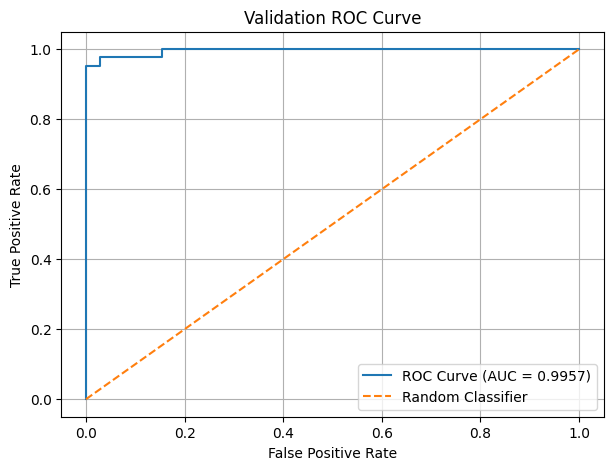

In [106]:
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_value:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid()

plt.show()

In [107]:
from sklearn.metrics import roc_auc_score

sklearn_auc = roc_auc_score(y_cancer_val, val_scores)

print("AUC from scratch:", auc_value)
print("AUC from sklearn:", sklearn_auc)
print("Absolute Difference:", abs(auc_value - sklearn_auc))

assert abs(auc_value - sklearn_auc) < 1e-6

AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
Absolute Difference: 1.1102230246251565e-16


In [108]:
# Try all distinct validation scores as thresholds
thresholds = np.unique(val_scores)

best_threshold = None

for threshold in thresholds:
    val_predictions = (val_scores >= threshold).astype(int)

    current_recall = recall_score(y_cancer_val, val_predictions)

    if current_recall == 1:
        best_threshold = threshold

print("Best Threshold:", best_threshold)

# Check recall at the selected threshold
best_val_predictions = (val_scores >= best_threshold).astype(int)

print("Validation Recall:",
      recall_score(y_cancer_val, best_val_predictions))

Best Threshold: 0.14602532493304418
Validation Recall: 1.0


In [109]:
# Predictions using the new threshold
y_test_pred_new = (
    predict_proba(X_cancer_test_bias, w) >= best_threshold
).astype(int)

# New confusion matrix
cm_new = confusion_matrix(y_cancer_test, y_test_pred_new)

# New precision and recall
precision_new = precision_score(y_cancer_test, y_test_pred_new)
recall_new = recall_score(y_cancer_test, y_test_pred_new)

print("Confusion Matrix at threshold =", best_threshold)
print(cm_new)

print("Precision:", precision_new)
print("Recall:", recall_new)

# Compare with threshold = 0.5
print("\nComparison:")
print("Precision at 0.5:", precision)
print("Recall at 0.5:", recall)
print("Precision at new threshold:", precision_new)
print("Recall at new threshold:", recall_new)

Confusion Matrix at threshold = 0.14602532493304418
[[66  6]
 [ 1 41]]
Precision: 0.8723404255319149
Recall: 0.9761904761904762

Comparison:
Precision at 0.5: 1.0
Recall at 0.5: 0.9523809523809523
Precision at new threshold: 0.8723404255319149
Recall at new threshold: 0.9761904761904762


In medical screening, reducing false negatives is very important because missing a malignant case can be dangerous.

Using a lower threshold increases recall, so the model detects more malignant cases. However, it also increases false positives, meaning that some benign cases are incorrectly classified as malignant.

At threshold 0.5, the model achieved 100% precision and 95.24% recall. At the new threshold (0.146), recall increased to 97.62%, while precision decreased to 87.23%.

The validation set contains only 43 positive cases. Therefore, the selected threshold may be sensitive to a small number of samples and may not generalize perfectly to new data.

For medical screening, a higher recall is generally preferred to reduce missed malignant cases, even if this leads to more false positives.

In [110]:
# Task 16
# Select mean radius and mean texture
feature_indices = [
    list(cancer.feature_names).index("mean radius"),
    list(cancer.feature_names).index("mean texture")
]

X_two = X_cancer_train[:, feature_indices]

X_two_val = X_cancer_val[:, feature_indices]
X_two_test = X_cancer_test[:, feature_indices]

print("Training shape:", X_two.shape)
print("Validation shape:", X_two_val.shape)
print("Testing shape:", X_two_test.shape)

Training shape: (341, 2)
Validation shape: (114, 2)
Testing shape: (114, 2)


In [111]:
# Standardize the two features
two_feature_scaler = Standardizer()

two_feature_scaler.fit(X_two)

X_two_train_std = two_feature_scaler.transform(X_two)
X_two_val_std = two_feature_scaler.transform(X_two_val)
X_two_test_std = two_feature_scaler.transform(X_two_test)

# Add bias column
X_two_train_bias = add_bias(X_two_train_std)

print("Training shape:", X_two_train_bias.shape)
print("Mean:", X_two_train_std.mean(axis=0))
print("Standard deviation:", X_two_train_std.std(axis=0))

Training shape: (341, 3)
Mean: [ 2.31811963e-16 -2.08370304e-16]
Standard deviation: [1. 1.]


In [112]:
# Train logistic regression using two features
w_two, losses_two, accuracies_two = logistic_gradient_descent(
    X_two_train_bias,
    y_cancer_train,
    lam=0,
    learning_rate=0.5,
    epochs=5000
)

print("Final Weights:")
print(w_two)

print("Final Training Loss:", losses_two[-1])
print("Final Training Accuracy:", accuracies_two[-1])

Final Weights:
[-0.7271724   3.65679417  1.00987153]
Final Training Loss: 0.24683361156367858
Final Training Accuracy: 0.9002932551319648


In [113]:
# Get mean and standard deviation from training data
mean = two_feature_scaler.mean
std = two_feature_scaler.std

# Convert weights to original coordinates
w_original = w_two[1:] / std

bias_original = w_two[0] - np.sum(w_two[1:] * mean / std)

w_original = np.insert(w_original, 0, bias_original)

print("Original Weights:")
print(w_original)

Original Weights:
[-19.64344417   1.01746116   0.23190058]


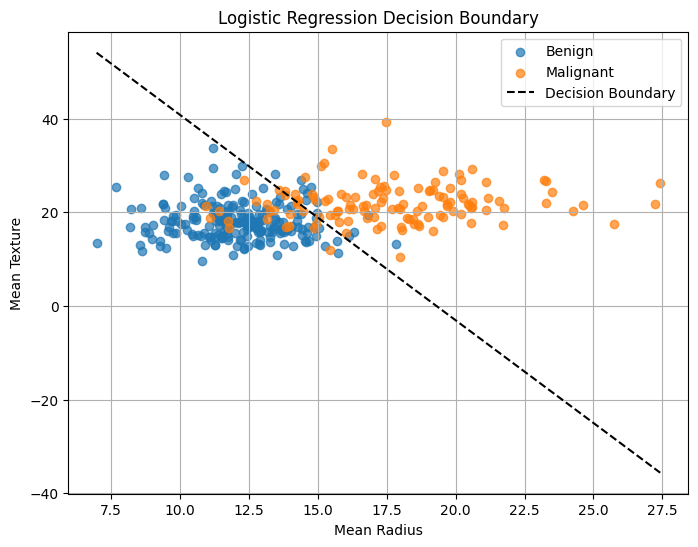

In [114]:
# Get original training features
x1 = X_two[:, 0]
x2 = X_two[:, 1]

# Create points for the decision boundary
x1_line = np.linspace(x1.min(), x1.max(), 100)

# Calculate the corresponding x2 values
x2_line = -(w_original[0] + w_original[1] * x1_line) / w_original[2]

# Plot the data
plt.figure(figsize=(8, 6))

plt.scatter(x1[y_cancer_train == 0], x2[y_cancer_train == 0],
            label="Benign", alpha=0.7)

plt.scatter(x1[y_cancer_train == 1], x2[y_cancer_train == 1],
            label="Malignant", alpha=0.7)

# Plot decision boundary
plt.plot(x1_line, x2_line, "k--", label="Decision Boundary")

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

In [115]:
# Calculate scores using standardized features
scores_standardized = X_two_train_bias @ w_two

# Add bias to original features
X_two_original_bias = add_bias(X_two)

# Calculate scores using original features and converted weights
scores_original = X_two_original_bias @ w_original

# Calculate maximum absolute difference
max_difference = np.max(
    np.abs(scores_standardized - scores_original)
)

print("Maximum Difference:", max_difference)

assert max_difference < 1e-9

print("Verification Passed!")

Maximum Difference: 3.552713678800501e-15
Verification Passed!


### Task 16 – Decision Boundary Visualization

A logistic regression model was trained using only two features: `mean radius` and `mean texture`.

The features were standardized using the training data only.

The model was trained with:
- Learning rate = 0.5
- Epochs = 5000
- Regularization parameter \(\lambda = 0\)

The final training accuracy was **90.03%**.

After training, the weights were converted back to the original feature scale:

- Bias = -19.6434
- Mean radius coefficient = 1.0175
- Mean texture coefficient = 0.2319

The decision boundary was plotted using the original features.

Finally, the scores calculated using the standardized features and the converted weights were compared.

The maximum difference was:

\[
3.5527 \times 10^{-15}
\]

Since this value is smaller than \(10^{-9}\), the verification passed.

**Conclusion:** The conversion of weights from standardized coordinates to original coordinates is correct, and both models produce the same scores.